In [ ]:
# %pip install matplotlib

In [1]:
import os
print(os.getcwd())

/home/hz1/comp370hw5


In [2]:
import subprocess

subprocess.run([
    "python",
    "scripts/borough_complaints.py",
    "-i", "data/311_records_2024_zipcode.csv",
    "-s", "2024-01-01",
    "-e", "2024-02-29",
    "-o", "data/jan_feb_complaints.csv"
], check=True)

CompletedProcess(args=['python', 'scripts/borough_complaints.py', '-i', 'data/311_records_2024_zipcode.csv', '-s', '2024-01-01', '-e', '2024-02-29', '-o', 'data/jan_feb_complaints.csv'], returncode=0)

In [3]:
import csv

complaint_counts = {}

with open("data/jan_feb_complaints.csv", "r", newline = "") as infile:
    reader = csv.DictReader(infile)

    for row in reader:
        complaint_type = row["Complaint Type"]
        count = int(row["Count"])

        complaint_counts[complaint_type] = (
        complaint_counts.get(complaint_type, 0) + count
        )

print(complaint_counts)

{'Building/Use': 2872, 'HEAT/HOT WATER': 81631, 'Noise - Vehicle': 4995, 'Blocked Driveway': 28608, 'Noise - Commercial': 8789, 'Illegal Parking': 79916, 'Noise - Residential': 43601, 'Missed Collection': 4045, 'Dirty Condition': 7567, 'Taxi Complaint': 834, 'Rodent': 5736, 'For Hire Vehicle Complaint': 3717, 'Noise': 8602, 'Street Condition': 10741, 'Street Light Condition': 5174, 'Noise - Street/Sidewalk': 8113, 'Food Establishment': 1647, 'DOOR/WINDOW': 8819, 'ELECTRIC': 5052, 'Elevator': 3181, 'Abandoned Vehicle': 11452, 'Encampment': 3937, 'WATER LEAK': 9177, 'UNSANITARY CONDITION': 19206, 'PLUMBING': 12057, 'Traffic Signal Condition': 8126, 'GENERAL': 5783, 'Indoor Air Quality': 1253, 'Panhandling': 610, 'Dead/Dying Tree': 744, 'Damaged Tree': 2934, 'Water System': 7317, 'Street Sign - Dangling': 727, 'Derelict Vehicles': 7417, 'Lost Property': 870, 'Air Quality': 1740, 'Emergency Response Team (ERT)': 589, 'Graffiti': 3078, 'Special Projects Inspection Team (SPIT)': 660, 'Outdoo

In [4]:
most_common = max(complaint_counts, key=complaint_counts.get)

print("Most abundant complaint type:", most_common)
print("Total complaints:", complaint_counts[most_common])

Most abundant complaint type: HEAT/HOT WATER
Total complaints: 81631


In [18]:
jan_feb_counts = {}

with open("data/jan_feb_complaints.csv", "r", newline="") as infile:
    reader = csv.DictReader(infile)

    for row in reader:
        if row["Complaint Type"] == most_common:
            borough = row["Borough"]
            count = int(row["Count"])

            jan_feb_counts[borough] = count

print(jan_feb_counts)
print("Total Jan-Feb:", sum(jan_feb_counts.values()))

{'BROOKLYN': 20915, 'BRONX': 30139, 'MANHATTAN': 17604, 'QUEENS': 12107, 'STATEN ISLAND': 866}
Total Jan-Feb: 81631


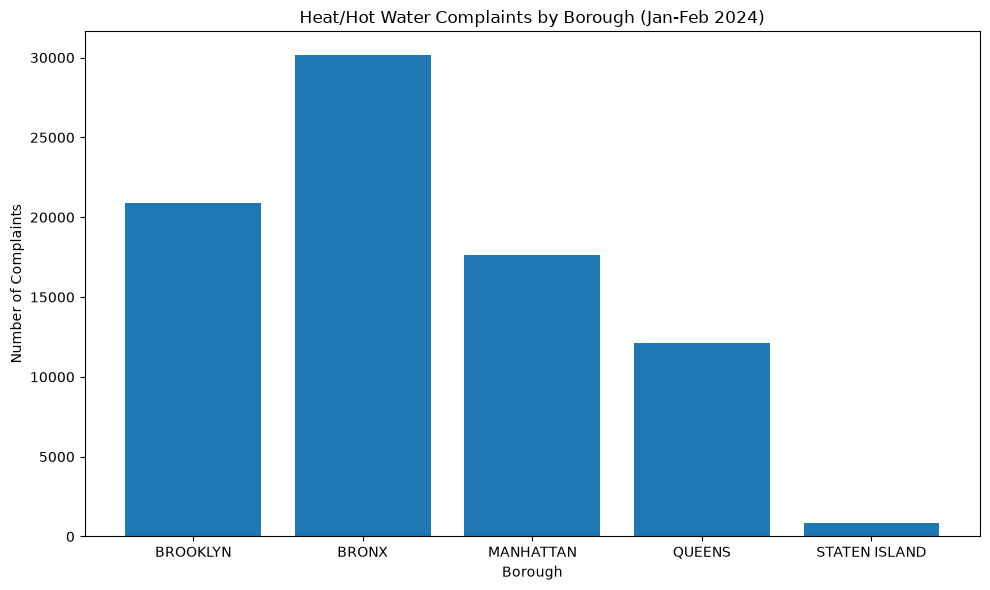

In [13]:
import matplotlib.pyplot as plt

borough = list(jan_feb_counts.keys())
counts = list(jan_feb_counts.values())

plt.figure(figsize = (10, 6))

plt.bar(borough, counts)

plt.xlabel("Borough")
plt.ylabel("Number of Complaints")
plt.title("Heat/Hot Water Complaints by Borough (Jan-Feb 2024)")

#plt.xticks(rotation = 30)
plt.tight_layout()
plt.show()

In [11]:
import subprocess

subprocess.run([
    "python",
    "scripts/borough_complaints.py",
    "-i", "data/311_records_2024_zipcode.csv",
    "-s", "2024-06-01",
    "-e", "2024-07-31",
    "-o", "data/jun_july_complaints.csv"
], check=True)

CompletedProcess(args=['python', 'scripts/borough_complaints.py', '-i', 'data/311_records_2024_zipcode.csv', '-s', '2024-06-01', '-e', '2024-07-31', '-o', 'data/jun_july_complaints.csv'], returncode=0)

In [17]:
jun_july_counts = {}

with open("data/jun_july_complaints.csv", "r", newline="") as infile:
    reader = csv.DictReader(infile)

    for row in reader:
        if row["Complaint Type"] == most_common:
            borough = row["Borough"]
            count = int(row["Count"])

            jun_july_counts[borough] = count

print(jun_july_counts)
print("Total June-July:", sum(jun_july_counts.values()))

{'BRONX': 2227, 'MANHATTAN': 1777, 'QUEENS': 835, 'STATEN ISLAND': 121, 'BROOKLYN': 1929}
Total June-July: 6889


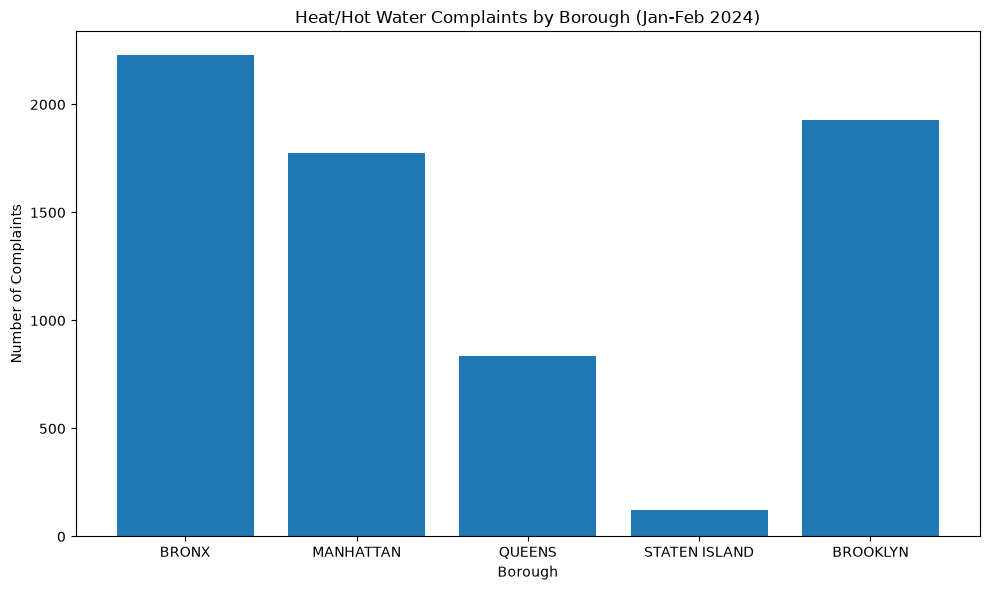

In [15]:
import matplotlib.pyplot as plt

borough = list(jun_july_counts.keys())
counts = list(jun_july_counts.values())

plt.figure(figsize = (10, 6))

plt.bar(borough, counts)

plt.xlabel("Borough")
plt.ylabel("Number of Complaints")
plt.title("Heat/Hot Water Complaints by Borough (Jan-Feb 2024)")

#plt.xticks(rotation = 30)
plt.tight_layout()
plt.show()

In [21]:
boroughs = sorted(set(jan_feb_counts) | set(jun_july_counts))

jan_feb = [borough_counts.get(borough, 0) for borough in boroughs]
jun_july = [jun_july_counts.get(borough, 0) for borough in boroughs]

print(boroughs)
print(jan_feb)
print(jun_july)

['BRONX', 'BROOKLYN', 'MANHATTAN', 'QUEENS', 'STATEN ISLAND']
[30139, 20915, 17604, 12107, 866]
[2227, 1929, 1777, 835, 121]


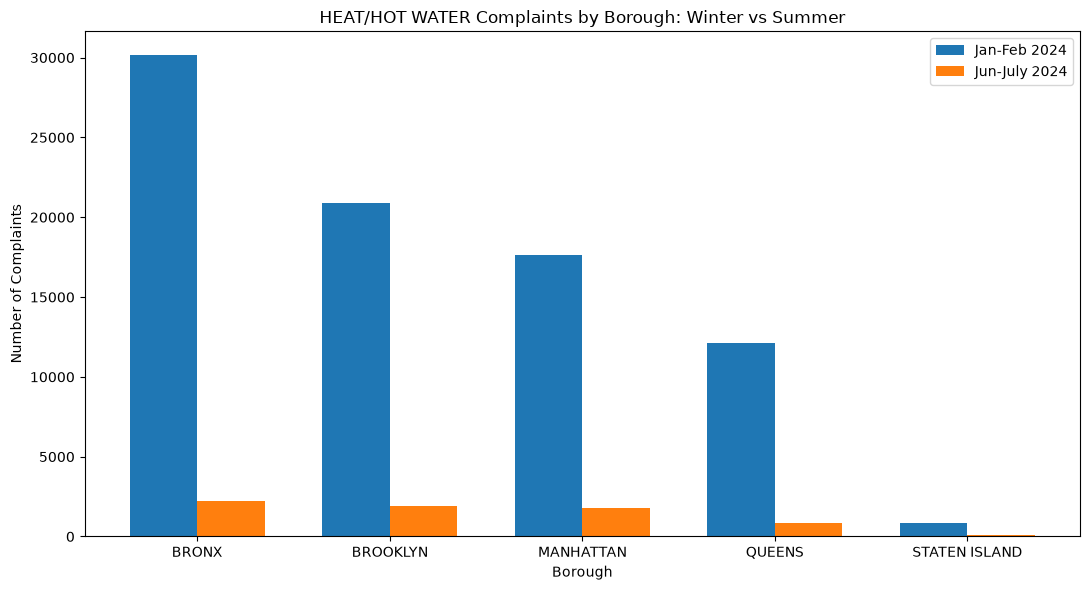

In [26]:
import matplotlib.pyplot as plt
import numpy as np

x = np.arange(len(boroughs))
width = 0.35

plt.figure(figsize = (11, 6))

plt.bar(x - width/2, jan_feb, width, label = "Jan-Feb 2024")
plt.bar(x + width/2, jun_july, width, label = "Jun-July 2024")

plt.xticks(x, boroughs)

plt.xlabel("Borough")
plt.ylabel("Number of Complaints")
plt.title("HEAT/HOT WATER Complaints by Borough: Winter vs Summer")

plt.legend()
plt.tight_layout()
plt.show()

In [28]:
winter_total = sum(jan_feb)
summer_total = sum(jun_july)

difference = summer_total - winter_total
percentage_change = difference / winter_total * 100

print("January–February total:", winter_total)
print("June–July total:", summer_total)
print("Difference:", difference)
print(f"Percentage change: {percentage_change:.2f}%")

January–February total: 81631
June–July total: 6889
Difference: -74742
Percentage change: -91.56%


In [32]:
for i, borough in enumerate(boroughs):
    difference = jun_july[i] - jan_feb[i]

    print(
        borough,
        "Winter:", jan_feb[i],
        "Summer:", jun_july[i],
        "Difference:", difference
    )

BRONX Winter: 30139 Summer: 2227 Difference: -27912
BROOKLYN Winter: 20915 Summer: 1929 Difference: -18986
MANHATTAN Winter: 17604 Summer: 1777 Difference: -15827
QUEENS Winter: 12107 Summer: 835 Difference: -11272
STATEN ISLAND Winter: 866 Summer: 121 Difference: -745
